In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/208.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/45.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/56.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/89.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/20.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/275.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/212.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/239.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/58.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/150.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food/6.jpg
/kaggle/input/datasets/trolukovich/food11-image-dataset/valid

In [2]:
import os

# Show all files and folders inside Kaggle input
for root, dirs, files in os.walk('/kaggle/input'):
    print(root)
    if files:
        print("  Files:", files[:5])

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/trolukovich
/kaggle/input/datasets/trolukovich/food11-image-dataset
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Fried food
  Files: ['208.jpg', '45.jpg', '56.jpg', '89.jpg', '20.jpg']
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Noodles-Pasta
  Files: ['45.jpg', '56.jpg', '89.jpg', '20.jpg', '58.jpg']
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Bread
  Files: ['208.jpg', '333.jpg', '45.jpg', '56.jpg', '89.jpg']
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Dessert
  Files: ['208.jpg', '473.jpg', '333.jpg', '45.jpg', '369.jpg']
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Seafood
  Files: ['208.jpg', '333.jpg', '45.jpg', '56.jpg', '89.jpg']
/kaggle/input/datasets/trolukovich/food11-image-dataset/validation/Soup
  Files: ['208.jpg', '473.jpg', '333.jpg',

In [3]:
import os
from collections import Counter

# Dataset path
DATASET_PATH = "/kaggle/input/datasets/trolukovich/food11-image-dataset"

# Folder paths
TRAIN_PATH = os.path.join(DATASET_PATH, "training")
VALIDATION_PATH = os.path.join(DATASET_PATH, "validation")
TEST_PATH = os.path.join(DATASET_PATH, "evaluation")

# Get class names
class_names = sorted([
    folder for folder in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, folder))
])

print("Food-11 Dataset Analysis")
print("=" * 50)

print("Number of classes:", len(class_names))
print("\nClasses:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

# Count images in each folder
def count_images(folder_path):
    count = 0
    for class_name in class_names:
        class_path = os.path.join(folder_path, class_name)
        if os.path.exists(class_path):
            count += len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
    return count

train_count = count_images(TRAIN_PATH)
validation_count = count_images(VALIDATION_PATH)
test_count = count_images(TEST_PATH)

print("\n" + "=" * 50)
print("Dataset Image Counts")
print("=" * 50)

print("Training images:", train_count)
print("Validation images:", validation_count)
print("Evaluation images:", test_count)
print("Total images:", train_count + validation_count + test_count)

Food-11 Dataset Analysis
Number of classes: 11

Classes:
0: Bread
1: Dairy product
2: Dessert
3: Egg
4: Fried food
5: Meat
6: Noodles-Pasta
7: Rice
8: Seafood
9: Soup
10: Vegetable-Fruit

Dataset Image Counts
Training images: 9866
Validation images: 3430
Evaluation images: 3347
Total images: 16643


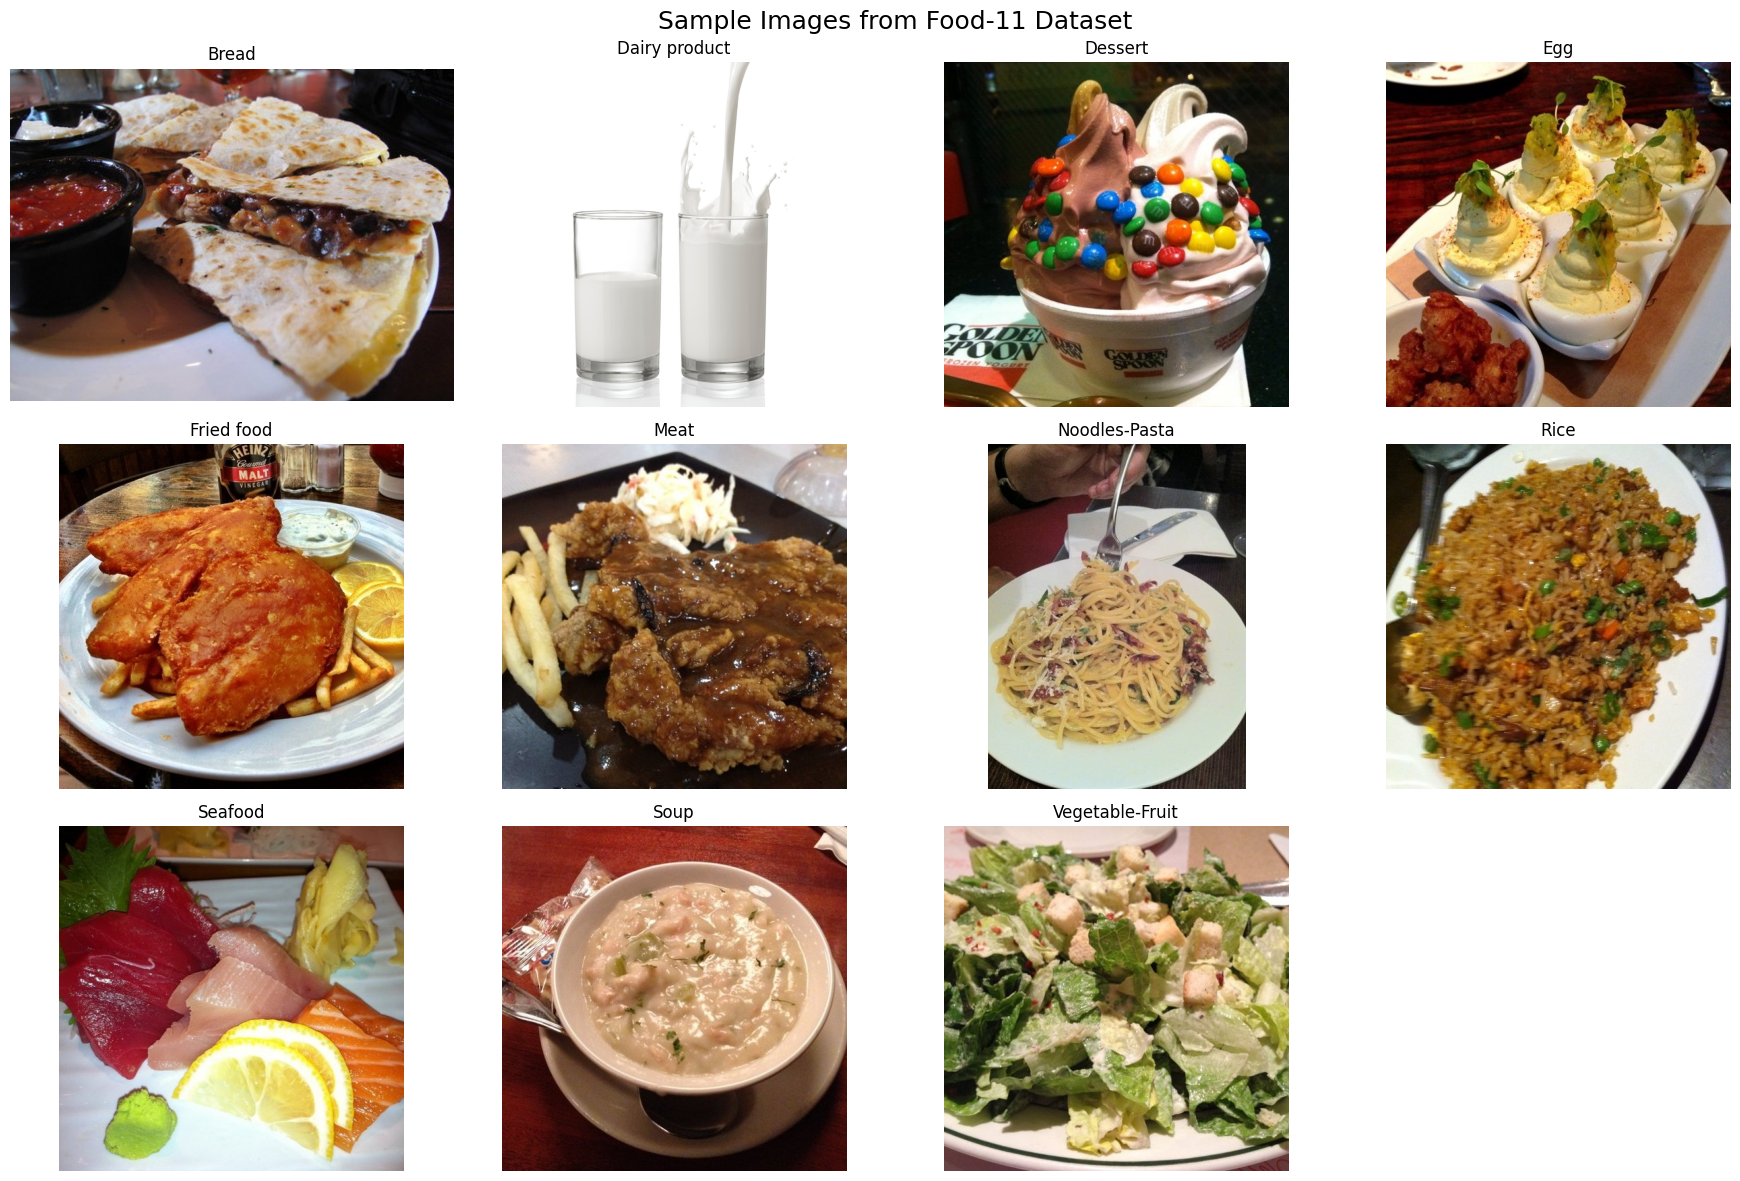

In [4]:
import matplotlib.pyplot as plt
from PIL import Image
import random
import os

# Select 11 random images, one from each class
plt.figure(figsize=(18, 12))

for i, class_name in enumerate(class_names):
    
    # Class folder
    class_folder = os.path.join(TRAIN_PATH, class_name)
    
    # Get image files
    image_files = [
        f for f in os.listdir(class_folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    
    # Select random image
    image_file = random.choice(image_files)
    image_path = os.path.join(class_folder, image_file)
    
    # Load image
    image = Image.open(image_path)
    
    # Display
    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.suptitle("Sample Images from Food-11 Dataset", fontsize=18)
plt.tight_layout()
plt.show()

In [5]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image size and batch size
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

# Data generators
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    horizontal_flip=True
)

validation_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

# Load training data
train_generator = train_datagen.flow_from_directory(
    TRAIN_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

# Load validation data
validation_generator = validation_datagen.flow_from_directory(
    VALIDATION_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

# Load evaluation/test data
test_generator = test_datagen.flow_from_directory(
    TEST_PATH,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

print("\nData preprocessing completed successfully!")
print("Number of classes:", train_generator.num_classes)
print("Training samples:", train_generator.samples)
print("Validation samples:", validation_generator.samples)
print("Test samples:", test_generator.samples)

Found 9866 images belonging to 11 classes.
Found 3430 images belonging to 11 classes.
Found 3347 images belonging to 11 classes.

Data preprocessing completed successfully!
Number of classes: 11
Training samples: 9866
Validation samples: 3430
Test samples: 3347


In [6]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create CNN model
model = models.Sequential([
    
    # Input layer
    layers.Input(shape=(128, 128, 3)),
    
    # First Convolution Block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Second Convolution Block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Third Convolution Block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    # Convert feature maps into a vector
    layers.Flatten(),
    
    # Fully connected layer
    layers.Dense(128, activation='relu'),
    
    # Dropout to reduce overfitting
    layers.Dropout(0.5),
    
    # Output layer - 11 food classes
    layers.Dense(11, activation='softmax')
])

# Display model architecture
model.summary()

2026-09-13 17:16:09.004856: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 11)             │         1,419 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,306,059 (12.61 MB)

 Trainable params: 3,306,059 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print("CNN model compiled successfully!")

CNN model compiled successfully!


In [8]:
EPOCHS = 15

history = model.fit(
    train_generator,
    epochs=EPOCHS,
    validation_data=validation_generator
)

Epoch 1/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 248s 795ms/step - accuracy: 0.2000 - loss: 2.2333 - val_accuracy: 0.2915 - val_loss: 2.0051
Epoch 2/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 204s 659ms/step - accuracy: 0.2832 - loss: 2.0338 - val_accuracy: 0.3531 - val_loss: 1.8895
Epoch 3/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 264s 666ms/step - accuracy: 0.3089 - loss: 1.9601 - val_accuracy: 0.3738 - val_loss: 1.8069
Epoch 4/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 204s 660ms/step - accuracy: 0.3395 - loss: 1.8895 - val_accuracy: 0.4280 - val_loss: 1.6658
Epoch 5/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 204s 659ms/step - accuracy: 0.3727 - loss: 1.8095 - val_accuracy: 0.4601 - val_loss: 1.6052
Epoch 6/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 202s 653ms/step - accuracy: 0.4107 - loss: 1.7151 - val_accuracy: 0.4685 - val_loss: 1.5685
Epoch 7/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 203s 656ms/step - accuracy: 0.4298 - loss: 1.6704 - val_accuracy: 0.4866 - val_loss: 1.5187
Epoch 8/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 201s 651ms/step - accuracy: 0.4532 -

In [9]:
model.save("/kaggle/working/food11_cnn_model.keras")

In [10]:
import os

print(os.path.exists("/kaggle/working/food11_cnn_model.keras"))

True


In [11]:
# Evaluate CNN model on the test/evaluation dataset

test_loss, test_accuracy = model.evaluate(test_generator)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

105/105 ━━━━━━━━━━━━━━━━━━━━ 43s 406ms/step - accuracy: 0.5817 - loss: 1.2282
Test Loss: 1.2282114028930664
Test Accuracy: 0.5817149877548218


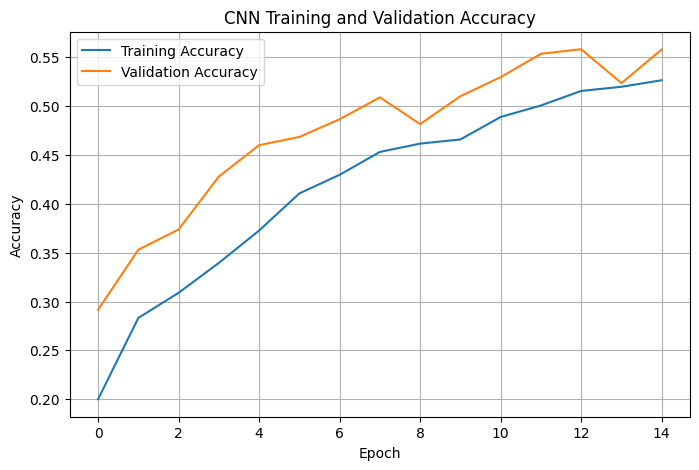

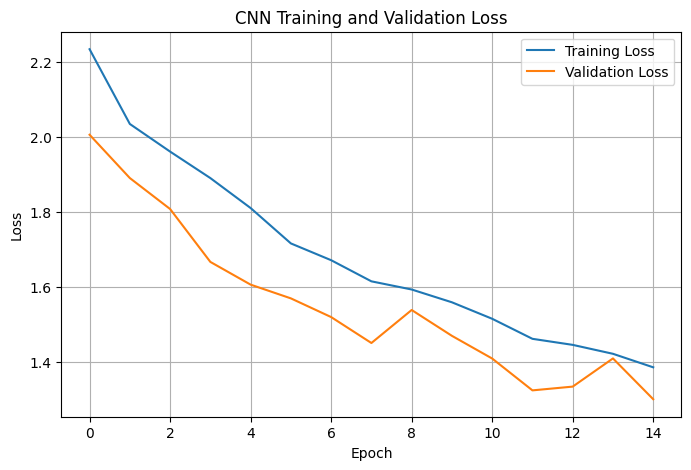

In [12]:
import matplotlib.pyplot as plt

# Training and Validation Accuracy
plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


# Training and Validation Loss
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

In [13]:
from sklearn.metrics import classification_report
import numpy as np

# Get predictions from test dataset
test_generator.reset()

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

# Classification report
print("Classification Report")
print("=" * 70)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

105/105 ━━━━━━━━━━━━━━━━━━━━ 23s 219ms/step
Classification Report
                 precision    recall  f1-score   support

          Bread       0.37      0.43      0.40       368
  Dairy product       0.52      0.22      0.30       148
        Dessert       0.44      0.63      0.52       500
            Egg       0.64      0.35      0.45       335
     Fried food       0.67      0.48      0.56       287
           Meat       0.57      0.81      0.67       432
  Noodles-Pasta       0.52      0.67      0.58       147
           Rice       0.65      0.27      0.38        96
        Seafood       0.73      0.50      0.60       303
           Soup       0.77      0.74      0.76       500
Vegetable-Fruit       0.84      0.84      0.84       231

       accuracy                           0.58      3347
      macro avg       0.61      0.54      0.55      3347
   weighted avg       0.61      0.58      0.58      3347



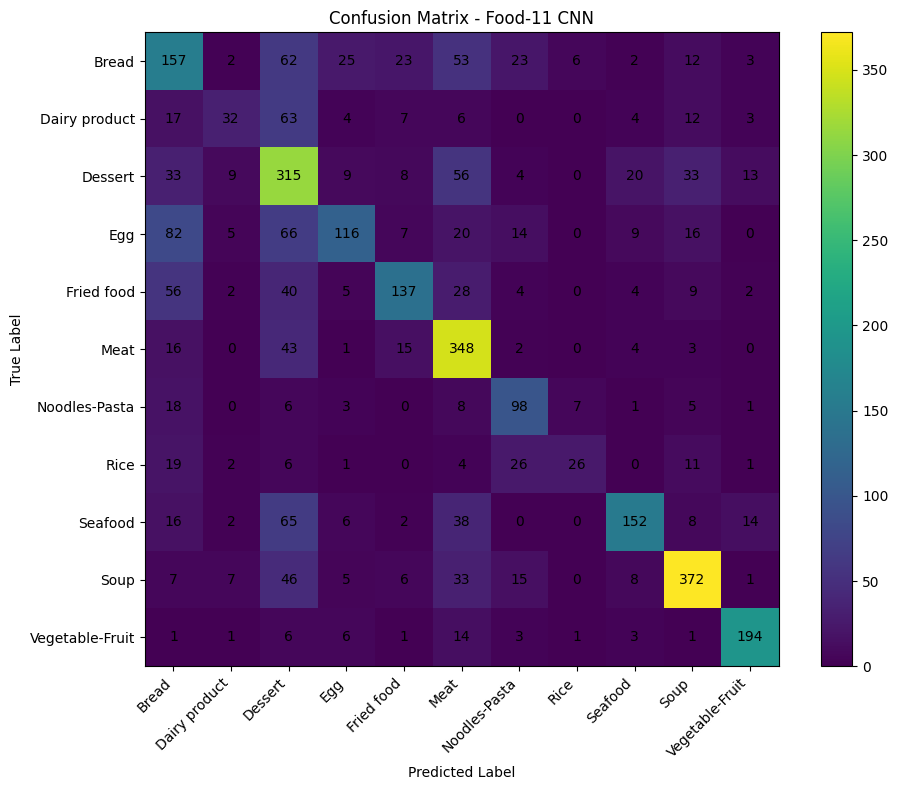

In [14]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))

plt.imshow(cm)
plt.title("Confusion Matrix - Food-11 CNN")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.xticks(
    np.arange(len(class_names)),
    class_names,
    rotation=45,
    ha="right"
)

plt.yticks(
    np.arange(len(class_names)),
    class_names
)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.colorbar()
plt.tight_layout()
plt.show()

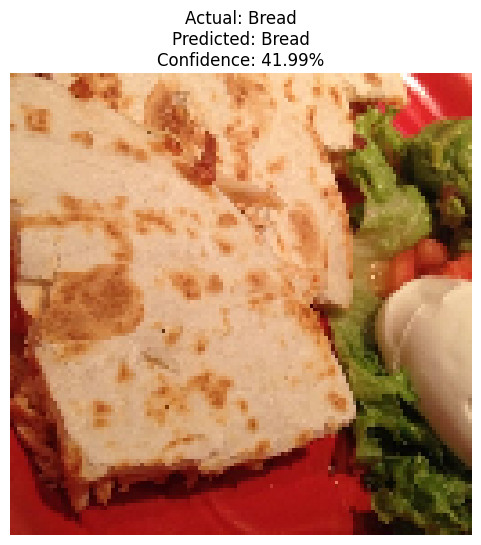

Actual Food: Bread
Predicted Food: Bread
Confidence: 41.99%


In [15]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

# Select one image from the test dataset
test_generator.reset()

images, labels = next(test_generator)

# Select first image
img = images[0]
true_label = np.argmax(labels[0])

# Predict
prediction = model.predict(np.expand_dims(img, axis=0), verbose=0)
predicted_label = np.argmax(prediction[0])
confidence = np.max(prediction[0]) * 100

# Display image
plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Actual: {class_names[true_label]}\n"
    f"Predicted: {class_names[predicted_label]}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Actual Food:", class_names[true_label])
print("Predicted Food:", class_names[predicted_label])
print(f"Confidence: {confidence:.2f}%")